In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("libraries imported successfully")

libraries imported successfully


In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [5]:
df = pd.read_csv("../datasets/superstore_sales.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Dataset Shape:",df.shape)
print("\nFirset 5 Records:")
display(df)

Dataset Shape: (9994, 9)

Firset 5 Records:


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,11/8/2016,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,6/12/2016,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,10/11/2015,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,10/11/2015,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2
...,...,...,...,...,...,...,...,...,...
9989,1/21/2014,South,Florida,Furniture,Furnishings,Consumer,25.2480,4.1028,3
9990,2/26/2017,West,California,Furniture,Furnishings,Consumer,91.9600,15.6332,2
9991,2/26/2017,West,California,Technology,Phones,Consumer,258.5760,19.3932,2
9992,2/26/2017,West,California,Office Supplies,Paper,Consumer,29.6000,13.3200,4


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    9994 non-null   object 
 1   Region        9994 non-null   object 
 2   State         9994 non-null   object 
 3   Category      9994 non-null   object 
 4   Sub-Category  9994 non-null   object 
 5   Segment       9994 non-null   object 
 6   Sales         9994 non-null   float64
 7   Profit        9994 non-null   float64
 8   Quantity      9994 non-null   int64  
dtypes: float64(2), int64(1), object(6)
memory usage: 702.8+ KB


In [8]:
print(df.columns.tolist())
print(df.isnull().sum())

['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment', 'Sales', 'Profit', 'Quantity']
Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64


In [9]:
df.describe()

,Sales,Profit,Quantity
count,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,3.789574
std,623.245101,234.260108,2.225110
min,0.444000,-6599.978000,1.000000
25%,17.280000,1.728750,2.000000
50%,54.490000,8.666500,3.000000
75%,209.940000,29.364000,5.000000
max,22638.480000,8399.976000,14.000000


In [10]:
mean_sales=df["Sales"].mean()
print("Mean Sales:",mean_sales)

Mean Sales: 229.85800083049827


In [11]:
median_sales=df["Sales"].median()
print("Median Sales:",median_sales)

Median Sales: 54.489999999999995


In [12]:
mode_sales=df["Sales"].mode()
print("Mode Sales:",mode_sales)

Mode Sales: 0    12.96
Name: Sales, dtype: float64


In [13]:
print("Mean:",df["Sales"].mean())
print("Median:",df["Sales"].median())
print("Mode:",df["Sales"].mode().tolist())

Mean: 229.85800083049827
Median: 54.489999999999995
Mode: [12.96]


In [14]:
central_tendency = pd.DataFrame({
    "Measure": ["Mean", "Median", "Mode"],
    "Sales Value": [
        df["Sales"].mean(),
        df["Sales"].median(),
        df["Sales"].mode().iloc[0]
    ]
})

display(central_tendency)

,Measure,Sales Value
0,Mean,229.858001
1,Median,54.490000
2,Mode,12.960000


In [15]:
sales_range=df["Sales"].max()-df["Sales"].min()
print("Maximum Sales:",df["Sales"].max())
print("Minimum Sales:",df["Sales"].min())
print("Range of Sales:",sales_range)

Maximum Sales: 22638.48
Minimum Sales: 0.444
Range of Sales: 22638.036


In [16]:
sales_variance=df["Sales"].var()
print("Sales Variance:",sales_variance)

Sales Variance: 388434.45530807565


In [17]:
sales_std=df["Sales"].std()
print("Sales Standard Deviation:",sales_std)

Sales Standard Deviation: 623.2451005086808


In [18]:
dispersion_summary = pd.DataFrame({
    "Measure": ["Range", "Variance", "Standard Deviation"],
    "Value": [
        sales_range,
        sales_variance,
        sales_std
    ]
})

display(dispersion_summary)

,Measure,Value
0,Range,22638.036000
1,Variance,388434.455308
2,Standard Deviation,623.245101


In [19]:
print("25th Percentile:", df["Sales"].quantile(0.25))
print("50th Percentile:", df["Sales"].quantile(0.50))
print("75th Percentile:", df["Sales"].quantile(0.75))

25th Percentile: 17.28
50th Percentile: 54.489999999999995
75th Percentile: 209.94


In [20]:
Q1=df["Sales"].quantile(0.25)
Q2=df["Sales"].quantile(0.50)
Q3=df["Sales"].quantile(0.75)
print("Q1:",Q1)
print("Q2:",Q2)
print("Q3:",Q3)

Q1: 17.28
Q2: 54.489999999999995
Q3: 209.94


In [21]:
IQR=Q3-Q1
print("Interquartile Range:",IQR)

Interquartile Range: 192.66


In [22]:
quartile_summary=pd.DataFrame({
    "Measure":["Q1","Q2","Q3","IQR"],
    "Sales Value":[Q1,Q2,Q3,IQR]
})
display(quartile_summary)

,Measure,Sales Value
0,Q1,17.28
1,Q2,54.49
2,Q3,209.94
3,IQR,192.66


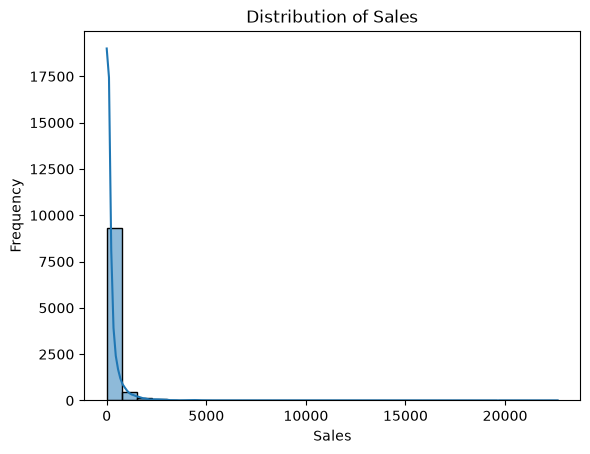

In [23]:
plt.Figure(figsize=(10,5))
sns.histplot(df["Sales"],bins=30,kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

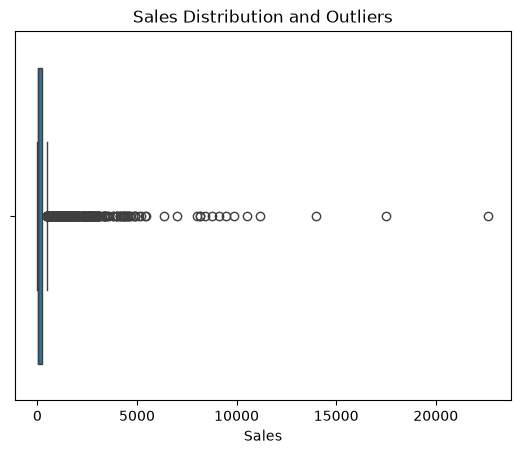

In [24]:
plt.Figure(figsize=(10,4))
sns.boxplot(x=df["Sales"])
plt.title("Sales Distribution and Outliers")
plt.xlabel("Sales")
plt.show()

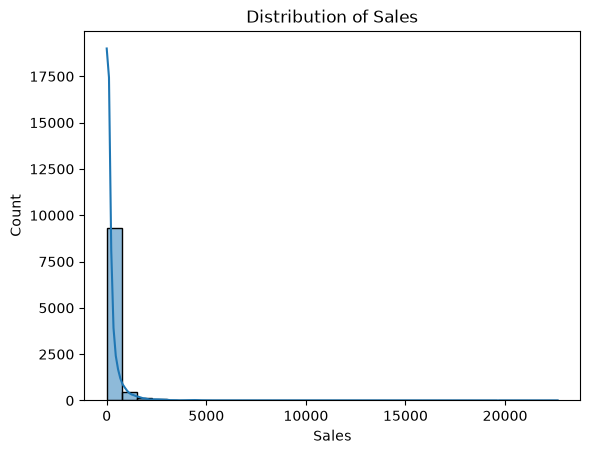

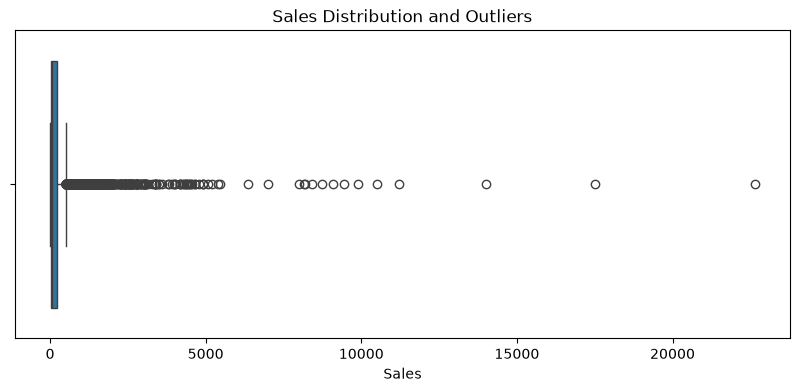

In [25]:
plt.Figure (figsize=(10,5))
sns.histplot(df["Sales"],bins=30,kde=True)
plt.title("Distribution of Sales")
plt.savefig("../charts/sales_histogram.png",bbox_inches="tight")
plt.show()
plt.figure(figsize=(10,4))
sns.boxplot(x=df["Sales"])
plt.title("Sales Distribution and Outliers")
plt.savefig("../charts/sales_boxplot.png",bbox_inches="tight")
plt.show()

In [26]:
total_sales=len(df)
profitable_sales=len(df[df["Profit"]>0])
probability_profit=profitable_sales/total_sales
print("Total Sales Records:",total_sales)
print("Profitable Sales Records:",profitable_sales)
print("Probability of Profit:",probability_profit)
print("Percentage of Profitable Sales:",probability_profit*100,"%")

Total Sales Records: 9994
Profitable Sales Records: 8058
Probability of Profit: 0.8062837702621573
Percentage of Profitable Sales: 80.62837702621573 %


In [27]:
east_sales=df[df["Region"]=="East"]
profitable_east_sales=east_sales[east_sales["Profit"]>0]
conditional_probability=(
    len(profitable_east_sales)/len(east_sales)
)
print("Total East Region Sales:",len(east_sales))
print("Profitable East Sales:",len(profitable_east_sales))
print("Probability of Profit in East Region:",conditional_probability)
print("Percentage:",conditional_probability*100,"%")

Total East Region Sales: 2848
Profitable East Sales: 2276
Probability of Profit in East Region: 0.7991573033707865
Percentage: 79.91573033707866 %


In [28]:
P_A=len(df[df["Region"]=="East"])/len(df)
P_B=len(df[df["Profit"]>0])/len(df)
P_A_and_B=len(
    df[(df["Region"]=="East")&(df["Profit"]>0)]
)/len(df)
print("P(A):",P_A)
print("P(B):",P_B)
print("P(A)xP(B):",P_A*P_B)
print("P(A and B):",P_A_and_B)

P(A): 0.2849709825895537
P(B): 0.8062837702621573
P(A)xP(B): 0.22976747825761695
P(A and B): 0.2277366419851911


In [29]:
profit_values=df["Profit"]
print("First 10 Profit Values:")
print(profit_values.head(10))
print("\nAverage Profit:",profit_values.mean())
print("Minimum Profit:",profit_values.min())
print("Maximum Profit:",profit_values.max())

First 10 Profit Values:
0     41.9136
1    219.5820
2      6.8714
3   -383.0310
4      2.5164
5     14.1694
6      1.9656
7     90.7152
8      5.7825
9     34.4700
Name: Profit, dtype: float64

Average Profit: 28.65689630778467
Minimum Profit: -6599.978
Maximum Profit: 8399.976


In [30]:
expected_profit=df["Profit"].mean()
print("Expected Profit:",expected_profit)

Expected Profit: 28.65689630778467


In [31]:
total_profit=df["Profit"].sum()
total_records=len(df)
expected_value=total_profit/total_records
print("Total Profit:",total_profit)
print("Total Records:",total_records)
print("Expected Value:",expected_value)

Total Profit: 286397.0217
Total Records: 9994
Expected Value: 28.65689630778467


In [32]:
%pip show scipy

Name: scipy
Version: 1.16.1
Summary: Fundamental algorithms for scientific computing in Python
Home-page: https://scipy.org/
Author: 
Author-email: 
License: Copyright (c) 2001-2002 Enthought, Inc. 2003, SciPy Developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions
 are met:

 1. Redistributions of source code must retain the above copyright
    notice, this list of conditions and the following disclaimer.

 2. Redistributions in binary form must reproduce the above
    copyright notice, this list of conditions and the following
    disclaimer in the documentation and/or other materials provided
    with the distribution.

 3. Neither the name of the copyright holder nor the names of its
    contributors may be used to endorse or promote products derived
    from this software without specific prior written permission.

 THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS A

In [33]:
from scipy import stats

In [34]:
sales_mean=df["Sales"].mean()
sales_std=df["Sales"].std()
print("Mean Sales:",sales_mean)
print("Standard Deviation:",sales_std)

Mean Sales: 229.85800083049827
Standard Deviation: 623.2451005086808


AttributeError: module 'numpy' has no attribute 'linespace'

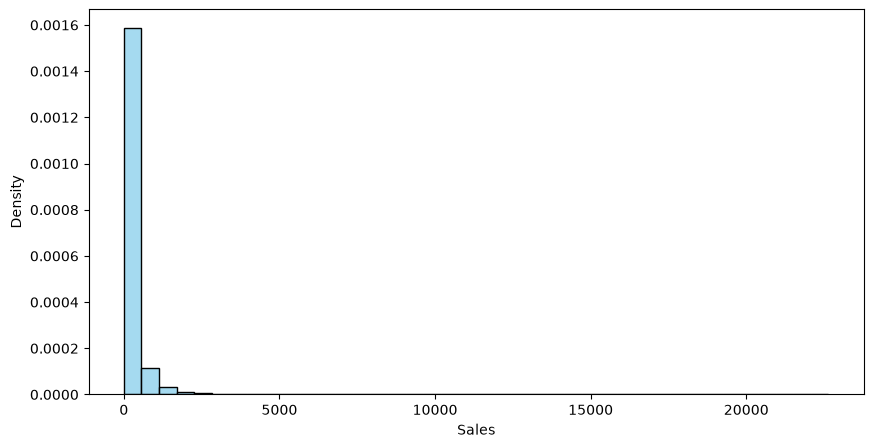

In [35]:
plt.figure(figsize=(10,5))
sns.histplot(
    df["Sales"],
    bins=40,
    stat="density",
    color="Skyblue",
    label="Actual Sales Distribution"
)
x=np.linespace(
    df["Sales"].min(),
    df["Sales"].max(),
    1000
)
y=stats.norm.pdf(x,sales_mean,sales_std)
plt.plot("Normal Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Density")
plt.legend()
plt.show()

In [ ]:
uniform_data=np.random.uniform(
    low=10,
    high=100,
    size=1000
)
print("First 10 Values:")
print(uniform_data[:10])
print("Mean:",np.mean(uniform_data))
print("Minimum:",np.min(uniform_data))
print("Maximum:",np.max(uniform_data))

First 10 Values:
[64.04926449 40.05121992 82.68947146 72.77066015 82.15841236 29.26370898
 25.56707196 27.96185692 37.5747491  54.05348063]
Mean: 53.612206016850585
Minimum: 10.253958622490787
Maximum: 99.83207555882558


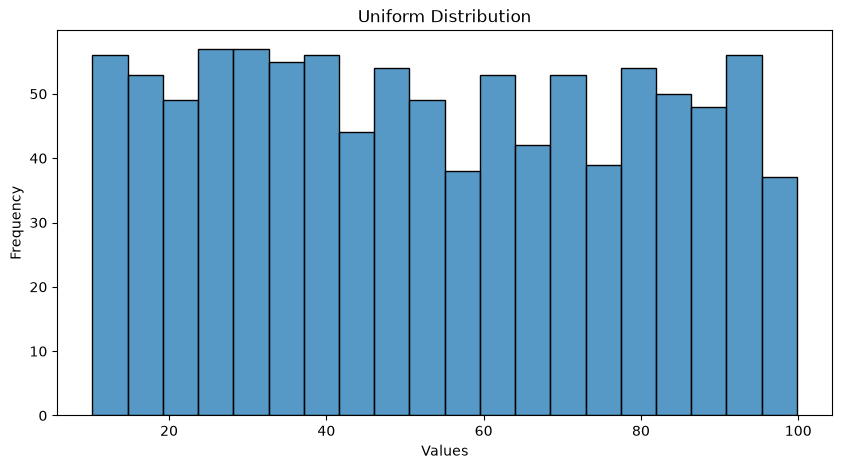

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(uniform_data,bins=20,kde=False)
plt.title("Uniform Distribution")
plt.xlabel("Values")
plt.ylabel("Frequency")
plt.show()


In [ ]:
from scipy.stats import binom
n=10
p=probability_profit
k=8
probability=binom.pmf(k,n,p)
print("Number of Trials:",n)
print("Probability of Success:",p)
print("Number of Successes:",k)
print("Probability of Extra 8 Profitable Sales:", probability)
print("Percentage:",probability*100,"%")

NameError: name 'probability_profit' is not defined

In [ ]:
x=np.arange(0,n+1)
y=binom.pmf(x,n,p)
plt.figure(figsize=(10,5))
plt.bar(x,y)
plt.title("Binominal Distribution of Profitable Sales")
plt.xlabel("Number of Profitable Sales")
plt.ylabel("Probability")
plt.show()

NameError: name 'p' is not defined

In [ ]:
from scipy.stats import poisson
lambda_value=5
x=3
probability=poisson.pmf(x,lambda_value)
print("Average Events (Lambda):",lambda_value)
print("Number of Events:",x)
print("Probability od Exactly 3 Events:",probability)
print("Percentage:",probability*100,"%")

Average Events (Lambda): 5
Number of Events: 3
Probability od Exactly 3 Events: 0.1403738958142805
Percentage: 14.03738958142805 %


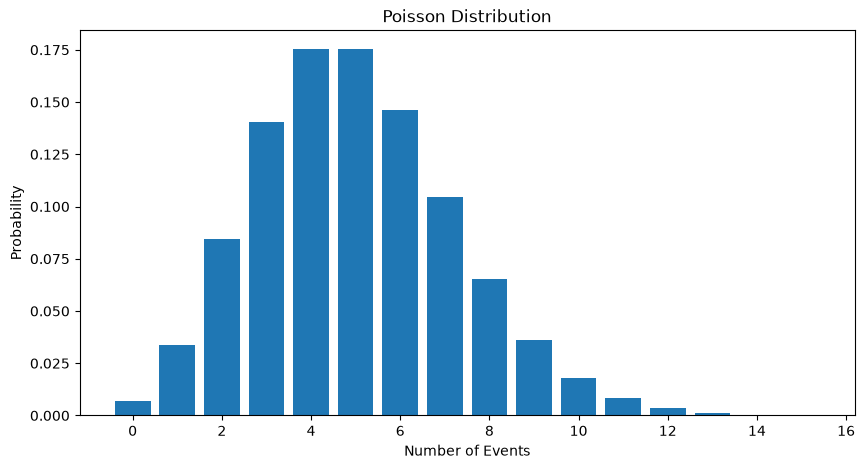

In [ ]:
x_values=np.arange(0,16)
y_values=poisson.pmf(x_values,lambda_value)
plt.figure(figsize=(10,5))
plt.bar(x_values,y_values)
plt.title("Poisson Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Probability")
plt.show()

In [ ]:
random_sample=df.sample(n=100,random_state=42)
print("Original Dataset Size:",len(df))
print("Random Sample Size:",len(random_sample))
print("\nFirst 5 Sample Records:")
display(random_sample.head())

Original Dataset Size: 9994
Random Sample Size: 100

First 5 Sample Records:


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
3125,6/11/2015,South,Florida,Office Supplies,Storage,Corporate,563.808,21.1428,4
1441,12/19/2017,West,California,Office Supplies,Binders,Consumer,36.672,11.4600,2
4510,11/10/2016,Central,Missouri,Furniture,Furnishings,Corporate,37.300,17.1580,2
39,12/27/2015,Central,Texas,Furniture,Chairs,Home Office,212.058,-15.1470,3
4509,5/23/2017,West,California,Furniture,Tables,Consumer,171.288,-6.4233,3


In [ ]:
print("Original Means Sales:",df["Sales"].mean())
print("Sample Mean Sales:",random_sample["Sales"].mean())

Original Means Sales: 229.85800083049827
Sample Mean Sales: 256.7012


In [ ]:
stratified_sample=(
    df.groupby("Region",group_keys=False)
    .sample(frac=0.10,random_state=42)
)
print("Original Dataset Size:",len(df))
print("Stratified Sample Size:",len(stratified_sample))
print("\nSample from Each Region:")
print(stratified_sample["Region"].value_counts())

Original Dataset Size: 9994
Stratified Sample Size: 999

Sample from Each Region:
Region
West       320
East       285
Central    232
South      162
Name: count, dtype: int64


In [ ]:
print("Original Regional Sales:")
print(df.groupby("Region")["Sales"].mean())
print("\nStratified Sample Regional Sales:")
print(stratified_sample.groupby("Region")["Sales"].mean())

Original Regional Sales:
Region
Central    215.772661
East       238.336110
South      241.803645
West       226.493233
Name: Sales, dtype: float64

Stratified Sample Regional Sales:
Region
Central    232.127135
East       226.304312
South      197.217401
West       232.747928
Name: Sales, dtype: float64


In [ ]:
interval=10
systematic_sample=df.iloc[::interval]
print("Original Dataset Size:",len(df))
print("Systematic Sample Size:",len(systematic_sample))
print("\nFisrt 10 Sample Records:")
display(systematic_sample.head(10))

Original Dataset Size: 9994
Systematic Sample Size: 1000

Fisrt 10 Sample Records:


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.960,41.9136,2
10,6/9/2014,West,California,Furniture,Tables,Consumer,1706.184,85.3092,9
20,8/27/2014,West,California,Office Supplies,Binders,Consumer,22.720,7.3840,4
30,9/17/2015,East,Pennsylvania,Office Supplies,Envelopes,Consumer,3.264,1.1016,2
40,12/27/2015,Central,Texas,Technology,Phones,Home Office,371.168,41.7564,4
50,4/18/2015,Central,Indiana,Office Supplies,Labels,Consumer,75.180,35.3346,6
60,6/17/2016,East,New York,Office Supplies,Binders,Consumer,48.480,16.3620,4
70,9/18/2016,East,New York,Office Supplies,Binders,Consumer,4.616,1.7310,1
80,6/12/2016,South,Alabama,Office Supplies,Binders,Corporate,16.740,8.0352,3
90,9/17/2016,West,California,Technology,Phones,Corporate,73.584,8.2782,2


In [ ]:
print("Original Mean Sales:",df["Sales"].mean())
print("Systematic Sample Mean Sales:",systematic_sample["Sales"].mean())

Original Mean Sales: 229.85800083049827
Systematic Sample Mean Sales: 265.99968649999994


In [ ]:
print("Original Region Distribution (%):")
print(
    df["Region"].value_counts(normalize=True)*100
)
print("\nSystematic Sample Region Distribution (%):")
print(
    systematic_sample["Region"].value_counts(normalize=True)*100
)

Original Region Distribution (%):
Region
West       32.049230
East       28.497098
Central    23.243946
South      16.209726
Name: proportion, dtype: float64

Systematic Sample Region Distribution (%):
Region
West       31.2
East       29.2
Central    24.3
South      15.3
Name: proportion, dtype: float64


In [ ]:
from scipy import stats
sample_mean=df["Sales"].mean()
benchmark=200
significance_level=0.05
t_statistics, p_value=stats.ttest_1samp(
    df["Sales"],
    popmean=benchmark
)
print("Sample Mean:",sample_mean)
print("Benchmark Mean:",benchmark)
print("T-Statistick:",t_statistics)
print("P-Value:",p_value)
print("Significance Level:",significance_level)
if p_value < significance_level:
    print("Decision: Reject Null Hypothesis")
else:
    print("Decision: Fail to Reject Null Hypothesis")

Sample Mean: 229.85800083049827
Benchmark Mean: 200
T-Statistick: 4.789294302012744
P-Value: 1.6977434726361298e-06
Significance Level: 0.05
Decision: Reject Null Hypothesis


In [ ]:
east_sales=df[df["Region"]=="East"]["Sales"]
west_sales=df[df["Region"]=="West"]["Sales"]
t_statistic, P_value=stats.ttest_ind(
    east_sales,
    west_sales,
    equal_var=False
)
print("East Mean Sales:",east_sales.mean())
print("West Mean Sales:",west_sales.mean())
print("T-Statistics:",t_statistic)
print("P-Value:",p_value)
if p_value <0.05:
    print("Decision: Reject Null Hypothesis")
else:
    print("Decision: Fail to Reject Null Hypothesis")

East Mean Sales: 238.3361095505618
West Mean Sales: 226.49323275054635
T-Statistics: 0.796108463300414
P-Value: 1.6977434726361298e-06
Decision: Reject Null Hypothesis


In [ ]:
east_sales=df[df["Region"]=="East"]["Sales"]
west_sales=df[df["Region"]=="West"]["Sales"]
ind_t, ind_p=stats.ttest_ind(
    east_sales,
    west_sales,
    equal_var=False
)
print("East Mean:",east_sales.mean())
print("West Mean:",west_sales.mean())
print("T-Statistics:",ind_t)
print("P-Value:",ind_p)
if ind_p <0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

East Mean: 238.3361095505618
West Mean: 226.49323275054635
T-Statistics: 0.796108463300414
P-Value: 0.42600271750321395
Fail to Reject Null Hypothesis


In [ ]:
df["Profit_Status"]=np.where(
    df["Profit"]>0,
    "Profitable",
    "Non-Profitable"
)
print(df["Profit_Status"].value_counts())

Profit_Status
Profitable        8058
Non-Profitable    1936
Name: count, dtype: int64


In [ ]:
contingency_table=pd.crosstab(
    df["Region"],
    df["Profit_Status"]
)
display(contingency_table)

Profit_Status,Non-Profitable,Profitable
Region,,
Central,752,1571
East,572,2276
South,272,1348
West,340,2863


In [ ]:
chi2_stat, p_value, dof, expected=stats.chi2_contingency(
    contingency_table
)
print("Chi-Square Statistics:",chi2_stat)
print("P-Value:",p_value)
print("Degrees of Freedom:",dof)
if p_value <0.05:
    print("Decision: Reject Null Hypothsis")
else:
    print("Decision: Fail to Reject Null Hypothesis")

Chi-Square Statistics: 416.4449200209841
P-Value: 6.065862844185004e-90
Degrees of Freedom: 3
Decision: Reject Null Hypothsis


In [ ]:
expected_table=pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)
display(expected_table)
print("Minimum Expected Frequency:",expected_table.min().min())

Profit_Status,Non-Profitable,Profitable
Region,,
Central,450.002802,1872.997198
East,551.703822,2296.296178
South,313.820292,1306.179708
West,620.473084,2582.526916


Minimum Expected Frequency: 313.82029217530516


In [ ]:
numerical_data=df.select_dtypes(include=["number"])
correlation_matrix=numerical_data.corr()
display(correlation_matrix)

,Sales,Profit,Quantity
Sales,1.000000,0.479064,0.200795
Profit,0.479064,1.000000,0.066253
Quantity,0.200795,0.066253,1.000000


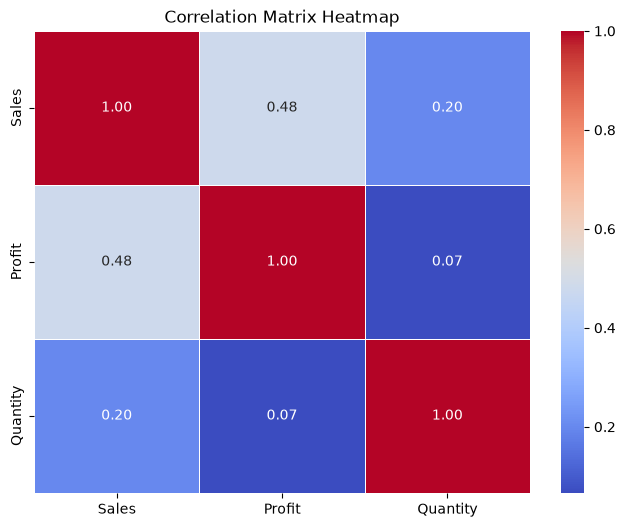

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
pearson_corr=df["Sales"].corr(df["Profit"],method="pearson")
print("Pearson Correlation:",pearson_corr)

Pearson Correlation: 0.4790643497377061


In [ ]:
spearman_corr = df["Sales"].corr(
    df["Profit"],
    method="spearman"
)

print("Spearman Correlation:", spearman_corr)

Spearman Correlation: 0.5184066611400607


In [ ]:
covariance_value = df["Sales"].cov(df["Profit"])

print("Covariance between Sales and Profit:", covariance_value)

Covariance between Sales and Profit: 69944.09658582548


In [ ]:
total_sales = df["Sales"].sum()
total_profit=df["Profit"].sum()
total_quantity=df["Quantity"].sum()
average_sales=df["Sales"].mean()
average_profit=df["Profit"].mean()
profit_margin=(total_profit/total_sales)*100
print("Total Sales:",total_sales)
print("Total Profit:",total_profit)
print("Total Quantity Sold:",total_quantity)
print("Average Sales:",average_sales)
print("Average Profit:",average_profit)
print("Profit Margin (%):",profit_margin)

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Quantity Sold: 37873
Average Sales: 229.85800083049827
Average Profit: 28.65689630778467
Profit Margin (%): 12.467217240315605


In [ ]:
df["Order Date"]=pd.to_datetime(df["Order Date"])
df["Month"]=df["Order Date"].dt.month
df["Year"]=df["Order Date"].dt.year
monthly_sales=df.groupby(
    ["Year","Month"]
)["Sales"].sum().reset_index()
display(monthly_sales.head(10))

,Year,Month,Sales
0,2014,1,14236.8950
1,2014,2,4519.8920
2,2014,3,55691.0090
3,2014,4,28295.3450
4,2014,5,23648.2870
5,2014,6,34595.1276
6,2014,7,33946.3930
7,2014,8,27909.4685
8,2014,9,81777.3508
9,2014,10,31453.3930


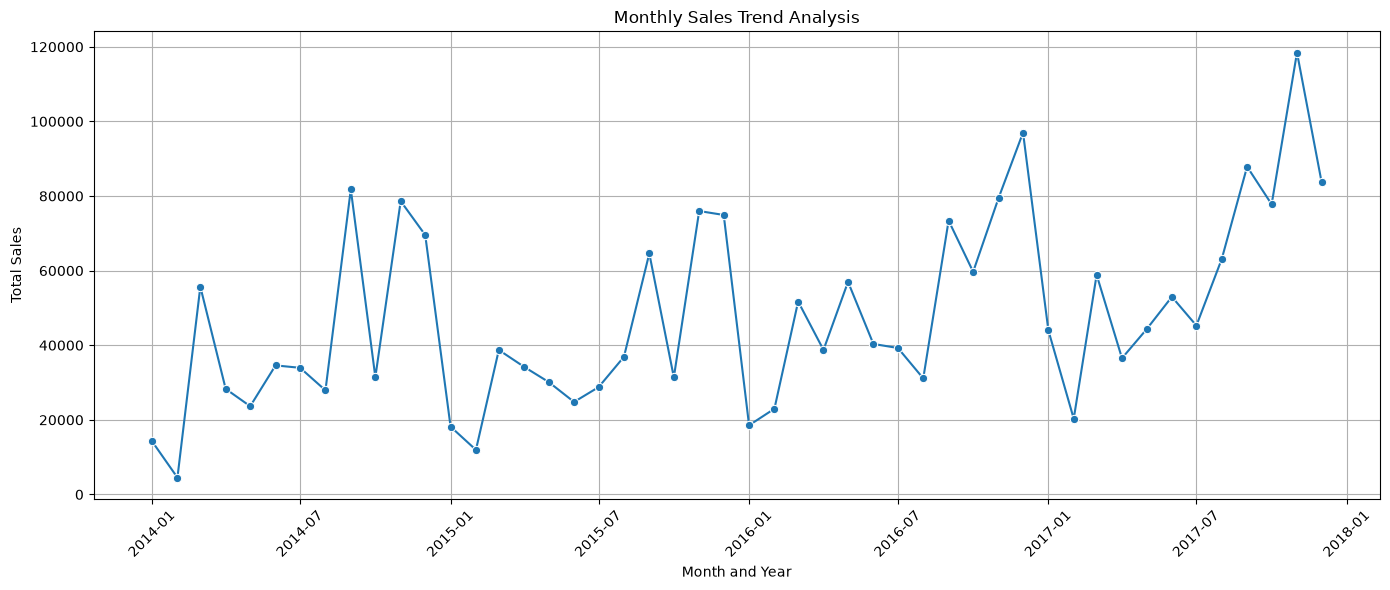

In [ ]:
monthly_sales["Date"]=pd.to_datetime(
    monthly_sales[["Year","Month"]].assign(Day=1)
)
monthly_sales=monthly_sales.sort_values("Date")
plt.figure(figsize=(14,6))
sns.lineplot(
    data=monthly_sales,
    x="Date",
    y="Sales",
    marker="o"
)
plt.title("Monthly Sales Trend Analysis")
plt.xlabel("Month and Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("../charts/monthly_sales_trend.png")
plt.show()

In [ ]:
region_analysis=df.groupby("Region").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
display(region_analysis)

,Region,Sales,Profit,Quantity
0,Central,501239.8908,39706.3625,8780
1,East,678781.2400,91522.7800,10618
2,South,391721.9050,46749.4303,6209
3,West,725457.8245,108418.4489,12266


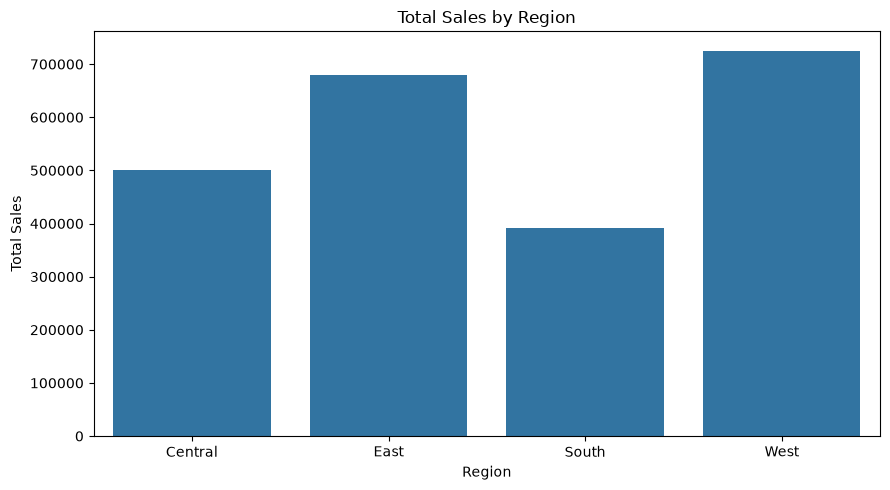

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Sales"
)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("../charts/regional_sales_analysis.png")
plt.show()

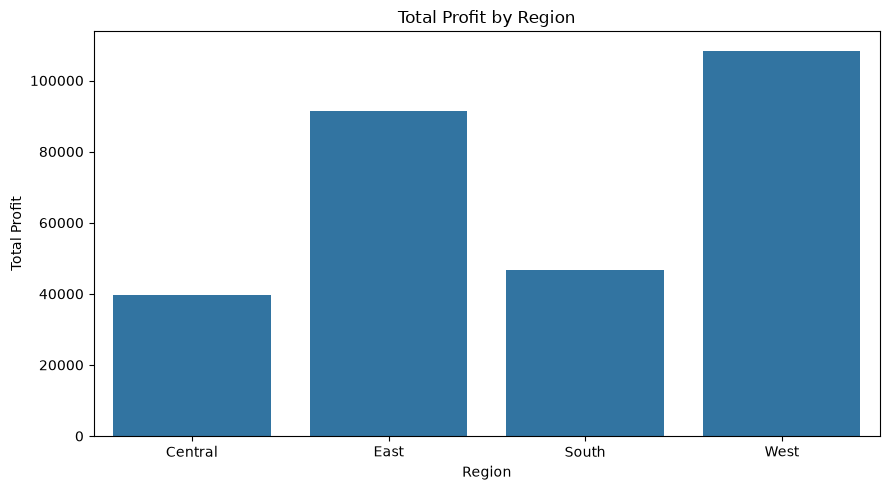

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Profit"
)
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig("../charts/regional_profit_analysis.png")
plt.show()

In [ ]:
category_analysis=df.groupby("Category").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
display(category_analysis)

,Category,Sales,Profit,Quantity
0,Furniture,741999.7953,18451.2728,8028
1,Office Supplies,719047.0320,122490.8008,22906
2,Technology,836154.0330,145454.9481,6939


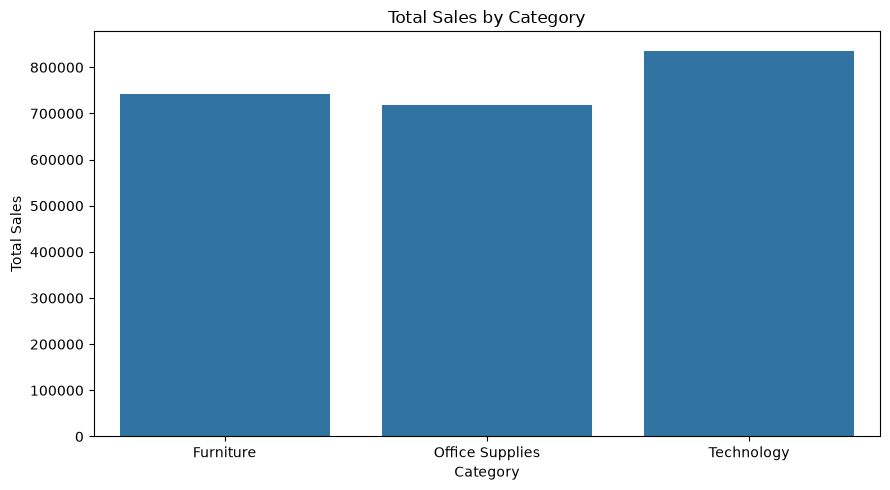

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Sales"
)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("../charts/category_sales_analysis.png")
plt.show()

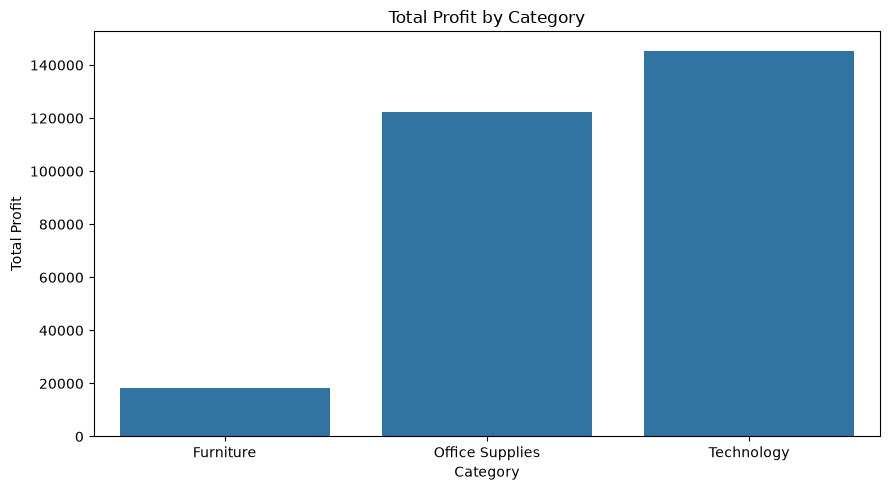

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Profit"
)
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig("../charts/category_profit_analysis.png")
plt.show()

In [ ]:
category_analysis["Profit_Margin"]=(
    category_analysis["Profit"]/category_analysis["Sales"]
)*100
display(category_analysis)

,Category,Sales,Profit,Quantity,Profit_Margin
0,Furniture,741999.7953,18451.2728,8028,2.486695
1,Office Supplies,719047.0320,122490.8008,22906,17.035158
2,Technology,836154.0330,145454.9481,6939,17.395712


In [ ]:
subcategory_analysis=df.groupby("Sub-Category").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
subcategory_analysis=subcategory_analysis.sort_values(
    by="Profit",
    ascending=False
)
display(subcategory_analysis)

,Sub-Category,Sales,Profit,Quantity
6,Copiers,149528.0300,55617.8249,234
13,Phones,330007.0540,44515.7306,3289
0,Accessories,167380.3180,41936.6357,2976
12,Paper,78479.2060,34053.5693,5178
3,Binders,203412.7330,30221.7633,5974
5,Chairs,328449.1030,26590.1663,2356
14,Storage,223843.6080,21278.8264,3158
1,Appliances,107532.1610,18138.0054,1729
9,Furnishings,91705.1640,13059.1436,3563
7,Envelopes,16476.4020,6964.1767,906


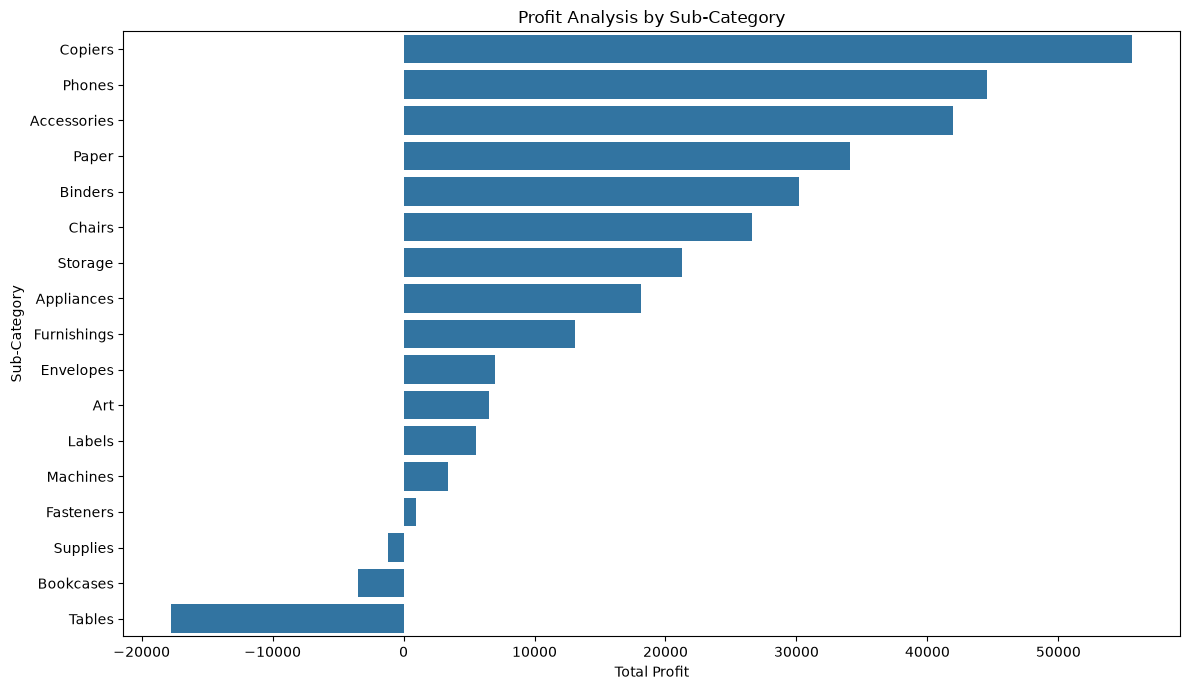

In [ ]:
plt.figure(figsize=(12,7))
sns.barplot(
    data=subcategory_analysis,
    x="Profit",
    y="Sub-Category"
)
plt.title("Profit Analysis by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("../charts/subcategory_profit_analysis.png")
plt.show()

In [ ]:
segment_analysis = df.groupby("Segment").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
display(segment_analysis)

,Segment,Sales,Profit,Quantity
0,Consumer,1.161401e+06,134119.2092,19521
1,Corporate,7.061464e+05,91979.1340,11608
2,Home Office,4.296531e+05,60298.6785,6744


In [ ]:
print(df.columns.tolist())

['Order Date', 'Region', 'State', 'Category', 'Sub-Category', 'Segment', 'Sales', 'Profit', 'Quantity', 'Profit_Status', 'Month', 'Year']


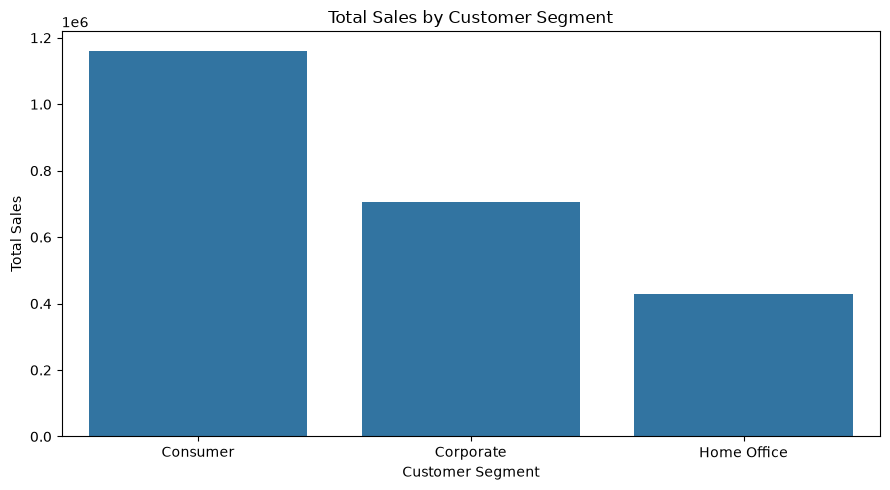

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Sales"
)
plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("../charts/segment_sales_analysis.png")
plt.show()

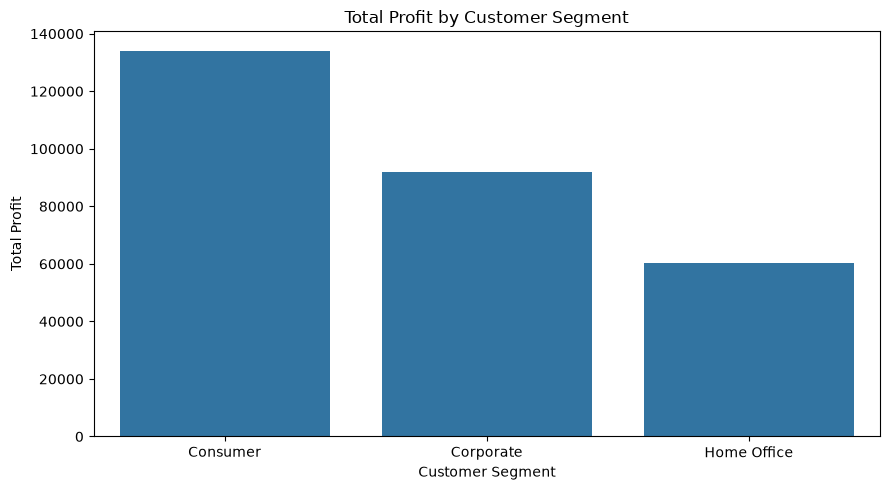

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=segment_analysis,
    x="Segment",
    y="Profit"
)
plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig("../charts/segment_profit_analysis.png")
plt.show()

In [ ]:
segment_analysis["Profit_Margin"]=(
    segment_analysis["Profit"]/segment_analysis["Sales"]
)*100
display(segment_analysis)

,Segment,Sales,Profit,Quantity,Profit_Margin
0,Consumer,1.161401e+06,134119.2092,19521,11.548050
1,Corporate,7.061464e+05,91979.1340,11608,13.025506
2,Home Office,4.296531e+05,60298.6785,6744,14.034269


In [ ]:
segment_analysis["Sales_Contribution"]=(
    segment_analysis["Sales"]/df["Sales"].sum()
)*100
display(segment_analysis)

,Segment,Sales,Profit,Quantity,Profit_Margin,Sales_Contribution
0,Consumer,1.161401e+06,134119.2092,19521,11.548050,50.557240
1,Corporate,7.061464e+05,91979.1340,11608,13.025506,30.739426
2,Home Office,4.296531e+05,60298.6785,6744,14.034269,18.703334


In [ ]:
total_sales=df["Sales"].sum()
total_profit=df["Profit"].sum()
total_orders=df["Order Date"].count()
total_quantity=df["Quantity"].sum()
average_sales=df["Sales"].mean()
profit_margin=(total_profit/total_sales)*100
print("EXECUTIVE DASHBOARD KPIs")
print("--------------------------")
print("Total Sales:",round(total_sales,2))
print("Total Profit:",round(total_profit,2))
print("Total Orders:",total_orders)
print("Total Quantity Sold:",total_quantity)
print("Average Sales:",round(average_sales,2))
print("profit Margin:",round(profit_margin,2),"%")

EXECUTIVE DASHBOARD KPIs
--------------------------
Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 9994
Total Quantity Sold: 37873
Average Sales: 229.86
profit Margin: 12.47 %


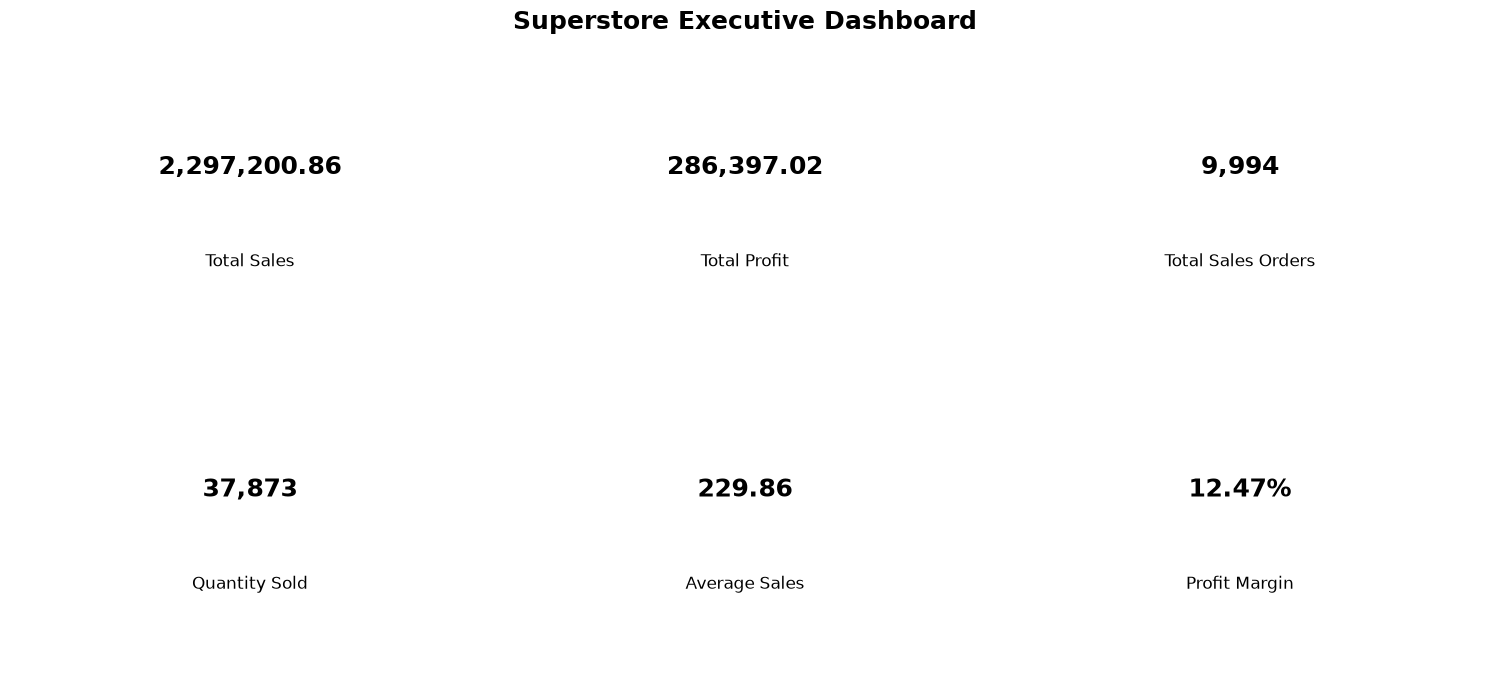

In [ ]:
fig,axes=plt.subplots(2,3,figsize=(15,7))
kpi_data=[
    ("Total Sales",f"{total_sales:,.2f}"),
    ("Total Profit",f"{total_profit:,.2f}"),
    ("Total Sales Orders",f"{total_orders:,}"),
    ("Quantity Sold",f"{total_quantity:,}"),
    ("Average Sales",f"{average_sales:,.2f}"),
    ("Profit Margin",f"{profit_margin:.2f}%")
]
for ax,(title,value)in zip(axes.flatten(),kpi_data):
    ax.text(0.5,0.6, value,ha="center",
            fontsize=18, fontweight="bold")
    ax.text(0.5,0.3,title,ha="center",fontsize=12)
    ax.set_axis_off()
plt.suptitle("Superstore Executive Dashboard",
             fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig("../charts/executive_kpi_dashboard.png")
plt.show()

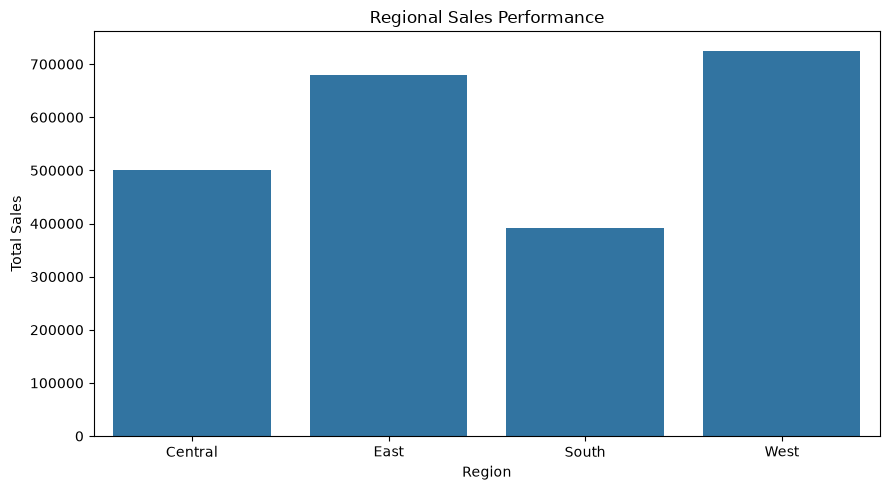

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=region_analysis,
    x="Region",
    y="Sales"
)
plt.title("Regional Sales Performance")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("../charts/dashboard_region_sales.png")
plt.show()

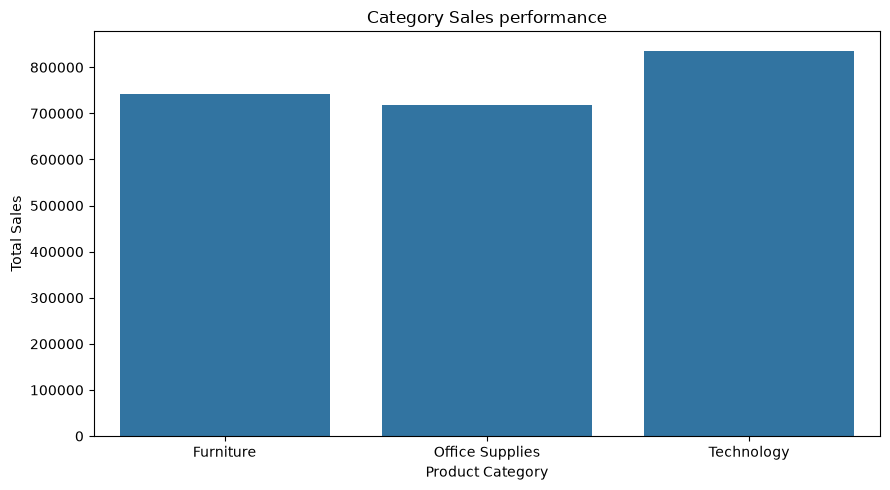

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Sales"
)
plt.title("Category Sales performance")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("../charts/dashboard_category_sales.png")
plt.show()

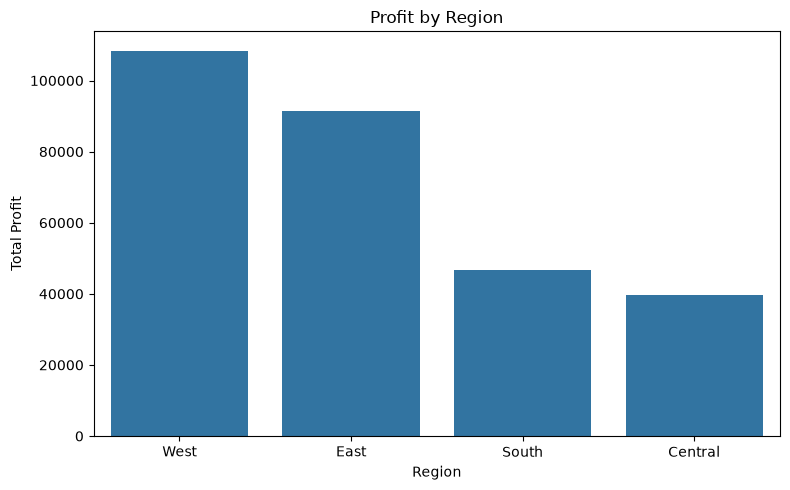

In [ ]:
regional_profit=df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=regional_profit.index,y=regional_profit.values)
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig("../charts/dashboard_regional_profit.png")
plt.show()

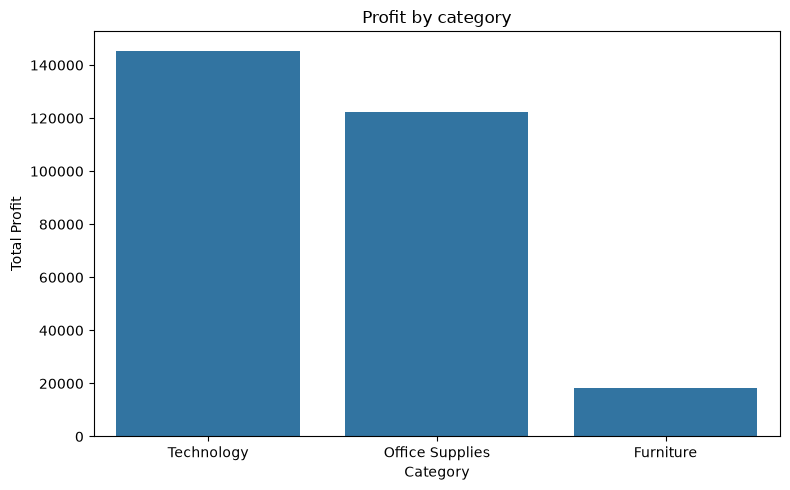

In [ ]:
category_profit=df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=category_profit.index,y=category_profit.values)
plt.title("Profit by category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.savefig("../charts/dashboard_category_profit.png")
plt.show()

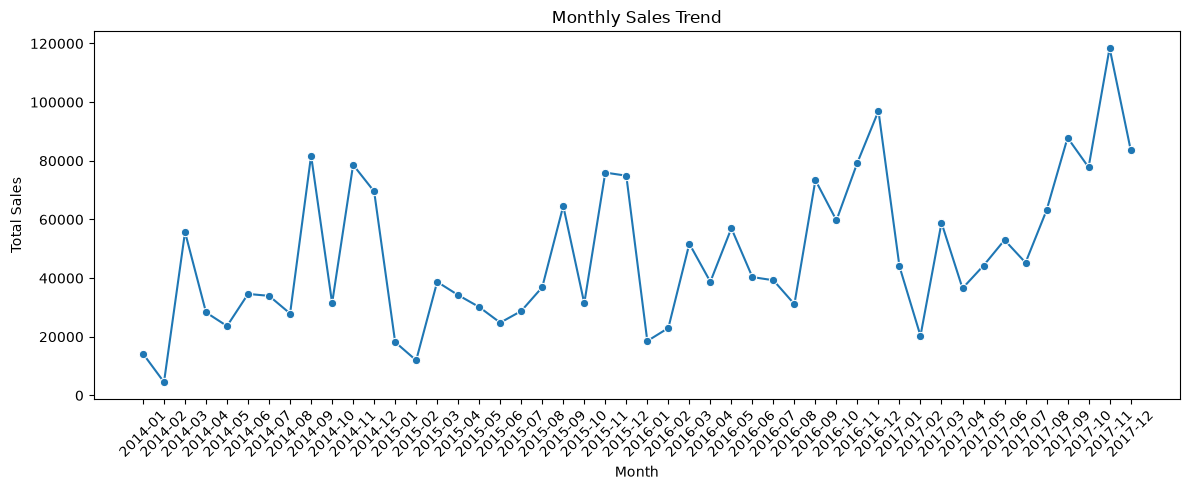

In [ ]:
monthly_sales=df.groupby(["Year","Month"])["Sales"].sum().reset_index()
monthly_sales["Period"]=(
    monthly_sales["Year"].astype(str)+"-"+
    monthly_sales["Month"].astype(str).str.zfill(2)
)
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly_sales,x="Period",y="Sales",marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../charts/dashboard_monthly_sales.png")
plt.show()

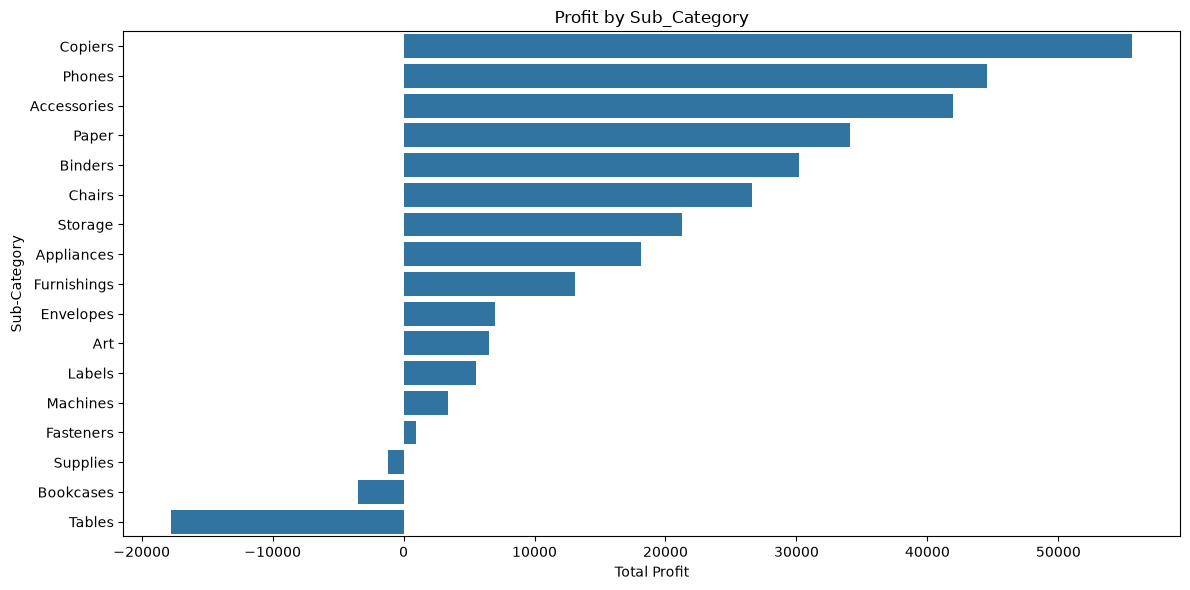

In [ ]:
subcategory_profit=(
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)
plt.figure(figsize=(12,6))
sns.barplot(
    x=subcategory_profit.values,
    y=subcategory_profit.index
)
plt.title("Profit by Sub_Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("../charts/dashboard_subcategory_profit.png")
plt.show()

In [ ]:
import os
print(os.listdir("../charts"))

['category_profit_analysis.png', 'category_sales_analysis.png', 'correlation_heatmap.png', 'dashboard_category_profit.png', 'dashboard_category_sales.png', 'dashboard_monthly_sales.png', 'dashboard_regional_profit.png', 'dashboard_region_sales.png', 'dashboard_subcategory_profit.png', 'executive_kpi_dashboard.png', 'final_executive_dashboard.png', 'monthly_sales_trend.png', 'regional_profit_analysis.png', 'regional_sales_analysis.png', 'sales_boxplot.png', 'sales_confidence_interval.png', 'sales_histogram.png', 'segment_profit_analysis.png', 'segment_sales_analysis.png', 'subcategory_profit_analysis.png']


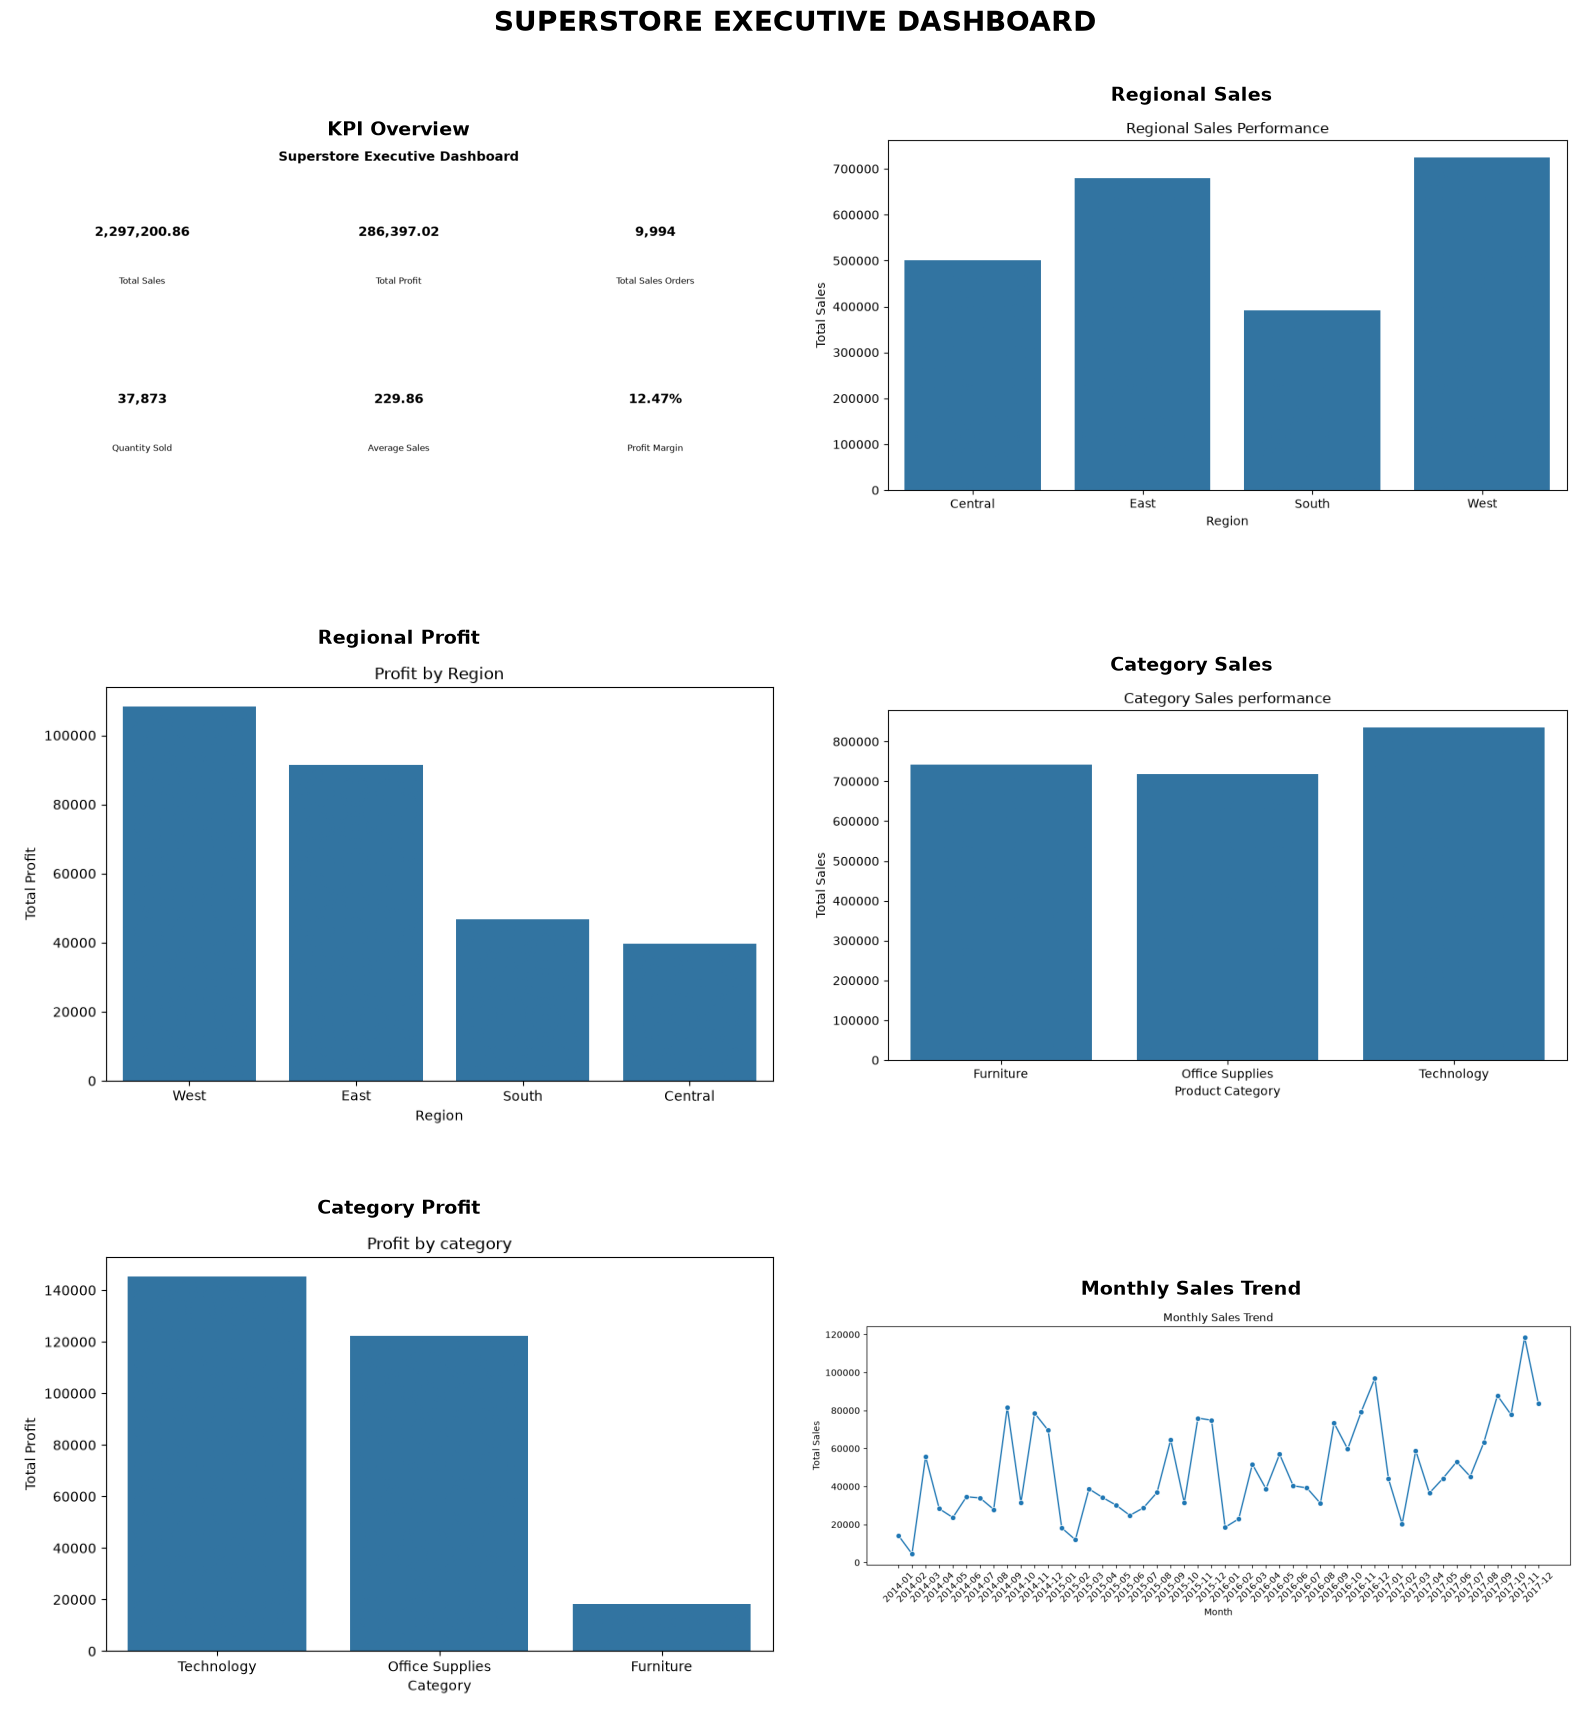

In [ ]:

chart_files = [
    ("KPI Overview", "../charts/executive_kpi_dashboard.png"),
    ("Regional Sales", "../charts/dashboard_region_sales.png"),
    ("Regional Profit", "../charts/dashboard_regional_profit.png"),
    ("Category Sales", "../charts/dashboard_category_sales.png"),
    ("Category Profit", "../charts/dashboard_category_profit.png"),
    ("Monthly Sales Trend", "../charts/dashboard_monthly_sales.png")
]

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

for ax, (title, file_path) in zip(axes.flatten(), chart_files):
    image = plt.imread(file_path)
    ax.imshow(image)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

plt.suptitle(
    "SUPERSTORE EXECUTIVE DASHBOARD",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("../charts/final_executive_dashboard.png", dpi=300)
plt.show()


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Charts folder exists:", os.path.exists("../charts"))
print("Files:", os.listdir("../charts"))

Current folder: c:\Users\joelt\OneDrive\Documents\Data-Analysis-with-Python\Task 3\notebooks
Charts folder exists: True
Files: ['category_profit_analysis.png', 'category_sales_analysis.png', 'correlation_heatmap.png', 'dashboard_category_profit.png', 'dashboard_category_sales.png', 'dashboard_monthly_sales.png', 'dashboard_regional_profit.png', 'dashboard_region_sales.png', 'dashboard_subcategory_profit.png', 'executive_kpi_dashboard.png', 'final_executive_dashboard.png', 'monthly_sales_trend.png', 'regional_profit_analysis.png', 'regional_sales_analysis.png', 'sales_boxplot.png', 'sales_confidence_interval.png', 'sales_histogram.png', 'segment_profit_analysis.png', 'segment_sales_analysis.png', 'subcategory_profit_analysis.png']


In [ ]:
import shutil
shutil.copy(
    "../charts/final_executive_dashboard.png",
    "../reports/final_executive_dashboard.png"
)
print("Dashboard successfully saved in reports folder")

Dashboard successfully saved in reports folder


In [ ]:
import scipy.stats as stats

sales = df["Sales"]

mean_sales = sales.mean()
standard_error = stats.sem(sales)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(sales) - 1,
    loc=mean_sales,
    scale=standard_error
)

print("Mean Sales:", mean_sales)
print("95% Confidence Interval:", confidence_interval)

Mean Sales: 229.85800083049827
95% Confidence Interval: (np.float64(217.63747489897534), np.float64(242.0785267620212))


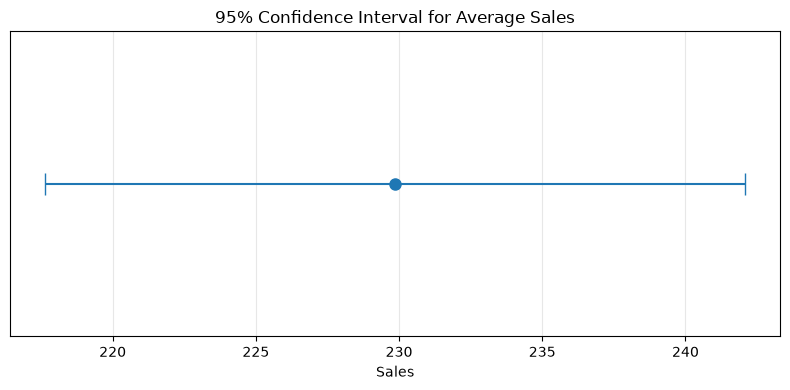

In [ ]:
plt.figure(figsize=(8,4))
plt.errorbar(
    x=mean_sales,
    y=1,
    xerr=[
        [mean_sales-confidence_interval[0]],
        [confidence_interval[1]-mean_sales]
    ],
    fmt="o",
    capsize=8,
    markersize=8
)
plt.title("95% Confidence Interval for Average Sales")
plt.xlabel("Sales")
plt.yticks([])
plt.grid(axis="x",alpha=0.3)
plt.tight_layout()
plt.savefig("../charts/sales_confidence_interval.png")
plt.show()

In [ ]:
confidence_report=pd.DataFrame({
    "Metric":["mean_sales","Lower Confidence Limit","Upper Confidence Limit"],
    "Value":[
        mean_sales,
        confidence_interval[0],
        confidence_interval[1]
    ]
})
confidence_report.to_csv(
    "../reports/confidence_interval_report.csv",
    index=False
)
print(confidence_report)
print("Confidence interval report saved successfully")

                   Metric       Value
0              mean_sales  229.858001
1  Lower Confidence Limit  217.637475
2  Upper Confidence Limit  242.078527
Confidence interval report saved successfully


In [ ]:
import openpyxl
print("Openpyxl is ready")

Openpyxl is ready


In [ ]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------

In [ ]:
kpi_report=pd.DataFrame({
    "KPI":[
        "Total Sales",
        "Total Profit",
        "Total Sales Records",
        "Total Quantity Sold",
        "Average Sales",
        "Profit Margin"
    ],
    "Value":[
        total_sales,
        total_profit,
        total_orders,
        total_quantity,
        average_sales,
        profit_margin
    ]
})
regional_report=df.groupby("Region").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
category_report=df.groupby("Category").agg({
    "Sales":"sum",
    "Profit":"sum",
    "Quantity":"sum"
}).reset_index()
with pd.ExcelWriter(
    "../reports/superstore_business_report.xlsx",
    engine="openpyxl"
)as writer:
    kpi_report.to_excel(writer,sheet_name="Business KPIs",index=False)
    regional_report.to_excel(writer, sheet_name="Regional Analysis",index=False)
    category_report.to_excel(writer,sheet_name="Regional Analysis",index=False)
    confidence_report.to_excel(writer,sheet_name="Confidence Interval",index=False)
    print("Excel report created successfully")

Excel report created successfully


In [ ]:
import reportlab
print("ReportLab is ready")

ReportLab is ready


In [ ]:
%pip install reportlab

  Using cached reportlab-5.1.0-py3-none-any.whl.metadata (1.6 kB)
Using cached reportlab-5.1.0-py3-none-any.whl (2.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [ ]:

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4

pdf_path = "../reports/superstore_business_report.pdf"

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

pdf_styles = getSampleStyleSheet()
content = []

content.append(Paragraph(
    "SUPERSTORE BUSINESS PERFORMANCE REPORT",
    pdf_styles["Title"]
))
content.append(Spacer(1, 15))

content.append(Paragraph("1. Project Overview", pdf_styles["Heading2"]))
content.append(Paragraph(
    "This project analyzes Superstore sales data using Python, "
    "Pandas, NumPy, SciPy, Matplotlib and Seaborn. "
    "The analysis focuses on business performance, statistical "
    "analysis, regional sales, category performance and business insights.",
    pdf_styles["BodyText"]
))
content.append(Spacer(1, 15))

content.append(Paragraph("2. Business KPI Summary", pdf_styles["Heading2"]))

kpi_data = [
    ["KPI", "Value"],
    ["Total Sales", f"{total_sales:,.2f}"],
    ["Total Profit", f"{total_profit:,.2f}"],
    ["Total Sales Records", f"{total_orders:,}"],
    ["Total Quantity Sold", f"{total_quantity:,}"],
    ["Average Sales", f"{average_sales:,.2f}"],
    ["Profit Margin", f"{profit_margin:.2f}%"]
]

kpi_table = Table(kpi_data, colWidths=[250, 180])
kpi_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.navy),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 7)
]))

content.append(kpi_table)
content.append(Spacer(1, 15))

content.append(Paragraph("3. Regional Performance", pdf_styles["Heading2"]))

for _, row in regional_report.iterrows():
    content.append(Paragraph(
        f"{row['Region']}: Sales = {row['Sales']:,.2f}, "
        f"Profit = {row['Profit']:,.2f}, "
        f"Quantity = {row['Quantity']:,.0f}",
        pdf_styles["BodyText"]
    ))

content.append(Spacer(1, 15))

content.append(Paragraph("4. Category Performance", pdf_styles["Heading2"]))

for _, row in category_report.iterrows():
    content.append(Paragraph(
        f"{row['Category']}: Sales = {row['Sales']:,.2f}, "
        f"Profit = {row['Profit']:,.2f}, "
        f"Quantity = {row['Quantity']:,.0f}",
        pdf_styles["BodyText"]
    ))

content.append(Spacer(1, 15))

content.append(Paragraph("5. Confidence Interval Analysis", pdf_styles["Heading2"]))

content.append(Paragraph(
    f"Mean Sales: {mean_sales:.2f}<br/>"
    f"95% Confidence Interval: "
    f"{confidence_interval[0]:.2f} to {confidence_interval[1]:.2f}",
    pdf_styles["BodyText"]
))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "6. Business Insights and Recommendations",
    pdf_styles["Heading2"]
))

recommendations = [
    "Technology generated the highest sales and profit among the three categories.",
    "Furniture had a low profit margin of approximately 2.49%; investigate its pricing and costs.",
    "The West region recorded the highest sales and profit.",
    "Tables recorded the largest sub-category loss; review their pricing and costs.",
    "Home Office had the highest profit margin among the customer segments."
]

for item in recommendations:
    content.append(Paragraph(
        "- " + item,
        pdf_styles["BodyText"]
    ))
    content.append(Spacer(1, 5))

doc.build(content)

print("PDF report created successfully!")
print("Saved at:", pdf_path)


PDF report created successfully!
Saved at: ../reports/superstore_business_report.pdf


In [ ]:
import shutil
shutil.copy(
    "../charts/final_executive_dashboard.png",
    "../screenshots/final_executive_dashboard.png"
)
print("Dashboard screenshot saved successfully")

Dashboard screenshot saved successfully


In [ ]:
import shutil
shutil.copy(
    "../charts/sales_confidence_interval.png",
    "../screenshots/sales_confidence_interval.png"
)
print("confidence interval screenshot saved successfully")

confidence interval screenshot saved successfully


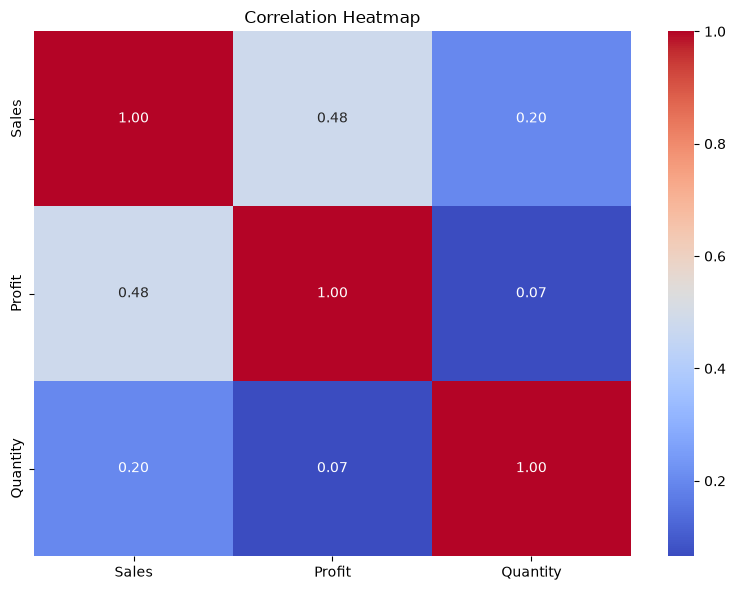

In [ ]:
correlation_data = df[["Sales", "Profit", "Quantity"]]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../charts/correlation_heatmap.png")
plt.show()

In [ ]:
shutil.copy(
    "../charts/correlation_heatmap.png",
    "../screenshots/correlation_heatmap.png"
)

print("correlation heatmap saved successfully")

correlation heatmap saved successfully


In [ ]:
import os
print(os.listdir("../charts"))

['category_profit_analysis.png', 'category_sales_analysis.png', 'dashboard_category_profit.png', 'dashboard_category_sales.png', 'dashboard_monthly_sales.png', 'dashboard_regional_profit.png', 'dashboard_region_sales.png', 'dashboard_subcategory_profit.png', 'executive_kpi_dashboard.png', 'final_executive_dashboard.png', 'monthly_sales_trend.png', 'regional_profit_analysis.png', 'regional_sales_analysis.png', 'sales_boxplot.png', 'sales_confidence_interval.png', 'sales_histogram.png', 'segment_profit_analysis.png', 'segment_sales_analysis.png', 'subcategory_profit_analysis.png']


In [ ]:
print(chi2_stat)
print(p_value)

416.4449200209841
6.065862844185004e-90


In [ ]:
hypothesis_report = pd.DataFrame({
    "Test": [
        "One-Sample T-Test",
        "Independent T-Test",
        "Chi-Square Test"
    ],

    "Test Staatistic": [
        4.789294302012744,
        0.796108463300414,
        416.4449200209841
    ],

    "P-Value": [
        0.0000016977434726361298,
        0.42600271750321395,
        6.065862844185004e-90
    ],

    "Conclusion": [
        "Reject Null Hypothesis",
        "Fail to Reject Null Hypothesis",
        "Reject Null Hypothesis"
    ]
})

hypothesis_report.to_csv(
    "../reports/hypothesis_testing_report.csv",
    index=False
)

print(hypothesis_report)
print("Hypothesis testing report saved successfully!")

In [ ]:

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle
)
from xml.sax.saxutils import escape
import re

# File paths
input_file = "../docs/technical_report.md"
output_file = "../docs/technical_report.pdf"

# Read Markdown file
with open(input_file, "r", encoding="utf-8") as file:
    content = file.read()

# PDF document setup
pdf = SimpleDocTemplate(
    output_file,
    pagesize=A4,
    rightMargin=0.55 * inch,
    leftMargin=0.55 * inch,
    topMargin=0.55 * inch,
    bottomMargin=0.55 * inch
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=20,
    leading=24,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#243B53"),
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading1"],
    fontSize=14,
    leading=17,
    textColor=colors.HexColor("#1F4E79"),
    spaceBefore=10,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="SubHeading",
    parent=styles["Heading2"],
    fontSize=11,
    leading=13,
    textColor=colors.HexColor("#2874A6"),
    spaceBefore=7,
    spaceAfter=4
))

styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontSize=8,
    leading=9.5,
    spaceAfter=5
))

story = []

# Page numbering
def add_page_number(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawCentredString(
        A4[0] / 2,
        0.3 * inch,
        f"Page {document.page}"
    )
    canvas.restoreState()


# Convert special scientific notation to PDF-friendly text
def clean_text(text):
    text = text.replace("× 10⁻⁹⁰", "e-90")
    text = text.replace("× 10-90", "e-90")
    text = text.replace("→", " -> ")
    return text


# Process Markdown content
lines = content.splitlines()
paragraph_lines = []
table_rows = []
in_table = False
in_code = False
code_lines = []


def flush_paragraph():
    if paragraph_lines:
        text = " ".join(paragraph_lines)
        text = clean_text(text)
        text = escape(text)

        # Markdown bold formatting
        text = re.sub(
            r"\*\*(.*?)\*\*",
            r"<b>\1</b>",
            text
        )

        # Inline code formatting
        text = re.sub(
            r"`(.*?)`",
            r"<font name='Courier'>\1</font>",
            text
        )

        story.append(
            Paragraph(text, styles["ReportBody"])
        )

        paragraph_lines.clear()


def flush_table():
    global table_rows

    if table_rows:
        cleaned_rows = []

        for row in table_rows:
            cells = [
                cell.strip()
                for cell in row.strip("|").split("|")
            ]

            # Ignore Markdown separator rows
            if not all(
                re.fullmatch(r"[-: ]+", cell or "-")
                for cell in cells
            ):
                cleaned_rows.append([
                    Paragraph(
                        escape(clean_text(cell)),
                        styles["ReportBody"]
                    )
                    for cell in cells
                ])

        if cleaned_rows:
            table = Table(
                cleaned_rows,
                repeatRows=1,
                hAlign="LEFT"
            )

            table.setStyle(TableStyle([
                (
                    "BACKGROUND",
                    (0, 0), (-1, 0),
                    colors.HexColor("#D9EAF7")
                ),
                (
                    "TEXTCOLOR",
                    (0, 0), (-1, 0),
                    colors.HexColor("#17365D")
                ),
                (
                    "GRID",
                    (0, 0), (-1, -1),
                    0.5, colors.grey
                ),
                (
                    "VALIGN",
                    (0, 0), (-1, -1),
                    "TOP"
                ),
                (
                    "FONTSIZE",
                    (0, 0), (-1, -1),
                    7.5
                ),
                (
                    "LEFTPADDING",
                    (0, 0), (-1, -1),
                    4
                ),
                (
                    "RIGHTPADDING",
                    (0, 0), (-1, -1),
                    4
                ),
                (
                    "TOPPADDING",
                    (0, 0), (-1, -1),
                    3
                ),
                (
                    "BOTTOMPADDING",
                    (0, 0), (-1, -1),
                    3
                )
            ]))

            from reportlab.platypus import KeepTogether
            story.append(KeepTogether([table, Spacer(1, 6)]))

        table_rows.clear()


# Read and format each Markdown line
for line in lines:

    stripped = line.strip()

    if stripped.startswith("```"):
        flush_paragraph()
        flush_table()

        if not in_code:
            in_code = True
            code_lines = []

        else:
            in_code = False

            # Convert Mermaid diagrams into readable workflows
            code_text = " ".join(code_lines)

            labels = re.findall(
                r"\[([^\]]+)\]|\{([^}]+)\}",
                code_text
            )

            labels = [a or b for a, b in labels]

            if labels:
                flow = " -> ".join(labels)

                story.append(
                    Paragraph(
                        escape(clean_text(flow)),
                        styles["ReportBody"]
                    )
                )

                story.append(Spacer(1, 5))

        continue

    if in_code:
        code_lines.append(line)
        continue

    if not stripped:
        flush_paragraph()
        flush_table()
        continue

    if stripped.startswith("|"):
        flush_paragraph()
        in_table = True
        table_rows.append(stripped)
        continue

    else:
        if in_table:
            flush_table()
            in_table = False

    if stripped == "---":
        flush_paragraph()
        story.append(Spacer(1, 5))
        continue

    if stripped.startswith("# "):
        flush_paragraph()

        title = escape(clean_text(stripped[2:]))

        story.append(
            Paragraph(title, styles["ReportTitle"])
        )
        continue

    if stripped.startswith("## "):
        flush_paragraph()

        heading = escape(clean_text(stripped[3:]))

        story.append(
            Paragraph(heading, styles["SectionHeading"])
        )
        continue

    if stripped.startswith("### "):
        flush_paragraph()

        heading = escape(clean_text(stripped[4:]))

        story.append(
            Paragraph(heading, styles["SubHeading"])
        )
        continue

    if stripped.startswith("- ") or re.match(
        r"^\d+\.\s", stripped
    ):
        flush_paragraph()

        item = re.sub(
            r"^(- |\d+\.\s)",
            "",
            stripped
        )

        story.append(
            Paragraph(
                "&#8226; " + escape(clean_text(item)),
                styles["ReportBody"]
            )
        )
        continue

    paragraph_lines.append(stripped)


# Process remaining content
flush_paragraph()
flush_table()

# Generate PDF
pdf.build(
    story,
    onFirstPage=add_page_number,
    onLaterPages=add_page_number
)

print("Technical report PDF created successfully!")
print("Saved location:", output_file)


Technical report PDF created successfully!
Saved location: ../docs/technical_report.pdf
